In [3]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

In [4]:
file_location = os.path.join('C:\\Users\\Austin\\Desktop\\cell_model\\fig_data', '*imt*')
filenames = glob.glob(file_location)

In [5]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)

In [6]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponential gaussian

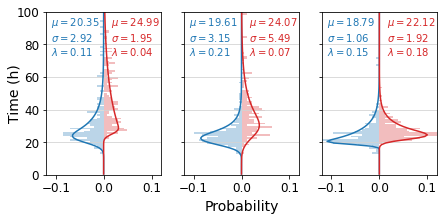

In [31]:
win = 21
pol = 2
size = (7,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 100

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)


h, edges =np.histogram(IMTs[0]["IMT_t"], bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)
h, edges =np.histogram(IMTs[1]["IMT_t"], bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)


h, edges =np.histogram(IMTs[4]["IMT_t"], bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)
h, edges =np.histogram(IMTs[5]["IMT_t"], bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)


h, edges =np.histogram(IMTs[6]["IMT_t"], bins=range(0,101), density=True)
out = axes[2].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[2].plot(fitted_curve, centers, color=c1)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)
h, edges =np.histogram(IMTs[7]["IMT_t"], bins=range(0,101), density=True)
out = axes[2].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2].plot(fitted_curve, centers, color=c2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)


ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Probability', labelpad=25)
ax.set_ylabel('Time (h)', labelpad=25)
#fig.tight_layout(rect=(0, 0, 1, 1))
plt.savefig('C:\\Users\Austin\Documents\\UMAP_projects\\nsclc_model\\fig1b.svg', bbox_inches='tight')